In [18]:
import pandas as pd

df = pd.read_csv("/content/covid_19_clean_complete.csv")

df.head(10)

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa
5,NaN,Antigua and Barbuda,17.06080,-61.796400,2020-01-22,0,0,0,0,Americas
6,NaN,Argentina,-38.41610,-63.616700,2020-01-22,0,0,0,0,Americas
7,NaN,Armenia,40.06910,45.038200,2020-01-22,0,0,0,0,Europe
8,Australian Capital Territory,Australia,-35.47350,149.012400,2020-01-22,0,0,0,0,Western Pacific
9,New South Wales,Australia,-33.86880,151.209300,2020-01-22,0,0,0,0,Western Pacific


In [19]:
print(df.columns)
print("Rows and columns:", df.shape)

print(df.isnull().sum())

Index(['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed',
       'Deaths', 'Recovered', 'Active', 'WHO Region'],
      dtype='object')
Rows and columns: (49068, 10)
Province/State    34404
Country/Region        0
Lat                   0
Long                  0
Date                  0
Confirmed             0
Deaths                0
Recovered             0
Active                0
WHO Region            0
dtype: int64


In [6]:
df["Date"] = pd.to_datetime(df["Date"])

print("Start date:", df["Date"].min())
print("End date:", df["Date"].max())

Start date: 2020-01-22 00:00:00
End date: 2020-07-27 00:00:00


In [7]:
latest_date = df["Date"].max()

latest_df = df[df["Date"] == latest_date].copy()

print("Latest date:", latest_date)
print("Rows in latest snapshot:", latest_df.shape[0])

latest_df.head()

Latest date: 2020-07-27 00:00:00
Rows in latest snapshot: 261


,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
48807,NaN,Afghanistan,33.93911,67.709953,2020-07-27,36263,1269,25198,9796,Eastern Mediterranean
48808,NaN,Albania,41.15330,20.168300,2020-07-27,4880,144,2745,1991,Europe
48809,NaN,Algeria,28.03390,1.659600,2020-07-27,27973,1163,18837,7973,Africa
48810,NaN,Andorra,42.50630,1.521800,2020-07-27,907,52,803,52,Europe
48811,NaN,Angola,-11.20270,17.873900,2020-07-27,950,41,242,667,Africa


# Some countries may appear more than once because of province or state entries.

In [8]:
country_df = latest_df.groupby("Country/Region", as_index=False).agg({
    "Lat": "mean",
    "Long": "mean",
    "Confirmed": "sum",
    "Deaths": "sum",
    "Recovered": "sum",
    "Active": "sum",
    "WHO Region": "first"
})

country_df.head()

,Country/Region,Lat,Long,Confirmed,Deaths,Recovered,Active,WHO Region
0,Afghanistan,33.93911,67.709953,36263,1269,25198,9796,Eastern Mediterranean
1,Albania,41.15330,20.168300,4880,144,2745,1991,Europe
2,Algeria,28.03390,1.659600,27973,1163,18837,7973,Africa
3,Andorra,42.50630,1.521800,907,52,803,52,Europe
4,Angola,-11.20270,17.873900,950,41,242,667,Africa


# We start with a very basic scatter plot using longitude and latitude.

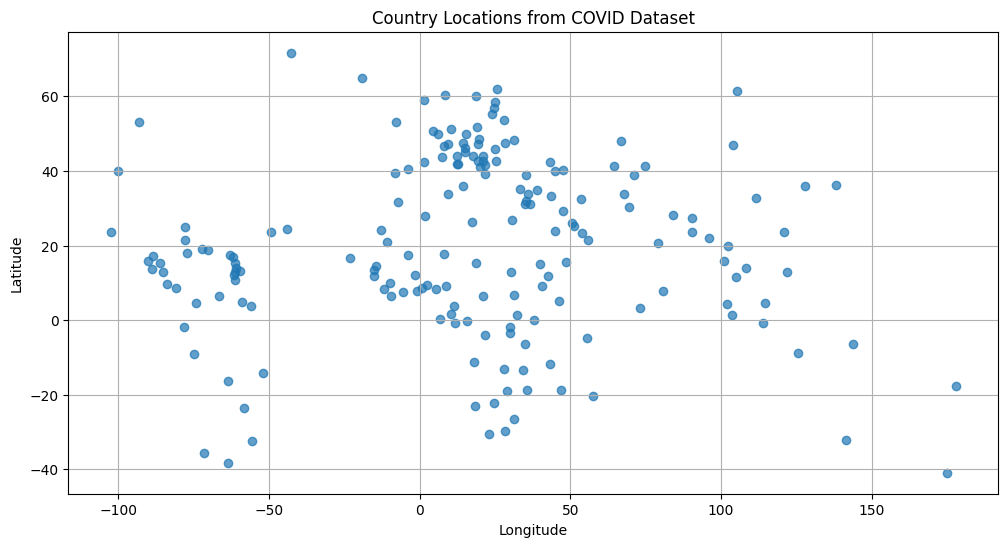

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.scatter(country_df["Long"], country_df["Lat"], alpha=0.7)

plt.title("Country Locations from COVID Dataset")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.show()

# Now we move from just location to a real dot map.
# Each dot still shows a country location, but now the dot size represents confirmed cases.

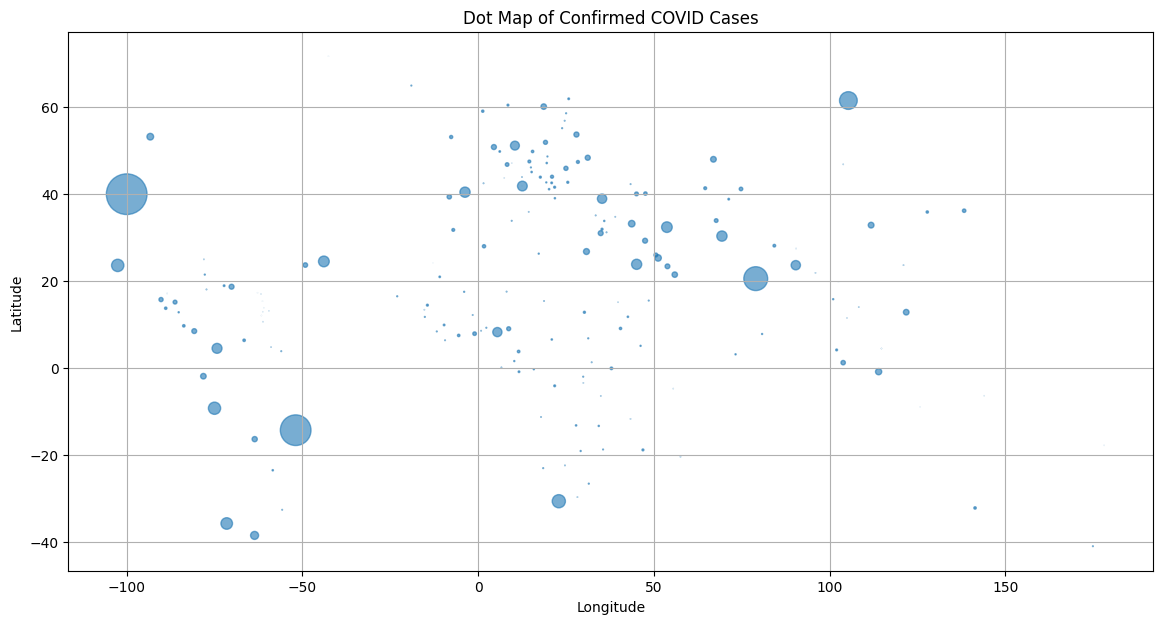

In [10]:
plt.figure(figsize=(14, 7))

plt.scatter(
    country_df["Long"],
    country_df["Lat"],
    s=country_df["Confirmed"] / 5000,   # reduce size to make it visible
    alpha=0.6
)

plt.title("Dot Map of Confirmed COVID Cases")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.show()

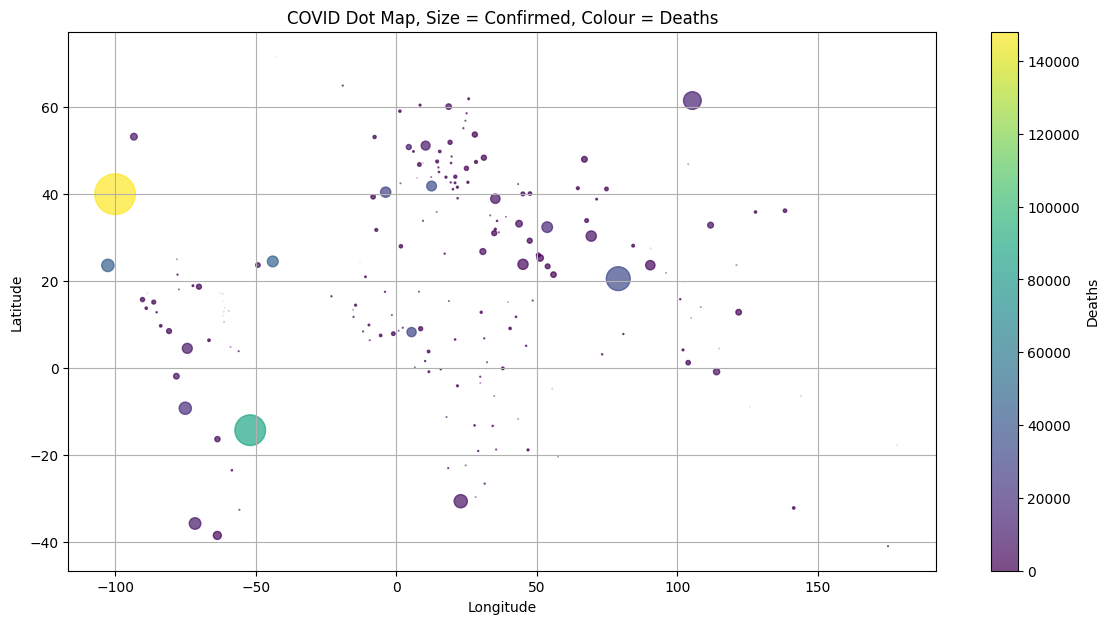

In [11]:
plt.figure(figsize=(14, 7))

scatter = plt.scatter(
    country_df["Long"],
    country_df["Lat"],
    s=country_df["Confirmed"] / 5000,
    c=country_df["Deaths"],
    alpha=0.7
)

plt.title("COVID Dot Map, Size = Confirmed, Colour = Deaths")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.colorbar(scatter, label="Deaths")
plt.grid(True)
plt.show()

# Interactive

In [12]:
import plotly.express as px

fig = px.scatter_geo(
    country_df,
    lat="Lat",
    lon="Long",
    size="Confirmed",
    color="WHO Region",
    hover_name="Country/Region",
    hover_data=["Confirmed", "Deaths", "Recovered", "Active"],
    title="Interactive COVID Dot Map by Country",
    projection="natural earth"
)

fig.show()

# Choropeth Visualisation :it colours the whole country based on the value, which is useful for comparing regions.

In [13]:
fig = px.choropleth(
    country_df,
    locations="Country/Region",
    locationmode="country names",
    color="Confirmed",
    hover_name="Country/Region",
    hover_data=["Deaths", "Recovered", "Active"],
    title="Choropleth Map of Confirmed COVID Cases"
)

fig.show()

# Choropleth map for deaths instead of confirmed cases

In [14]:
fig = px.choropleth(
    country_df,
    locations="Country/Region",
    locationmode="country names",
    color="Deaths",
    hover_name="Country/Region",
    hover_data=["Confirmed", "Recovered", "Active"],
    title="Choropleth Map of COVID Deaths"
)

fig.show()

# This dataset is very good for showing how something changes across time.

In [15]:

animated_df = df.groupby(["Date", "Country/Region"], as_index=False).agg({
    "Lat": "mean",
    "Long": "mean",
    "Confirmed": "sum",
    "Deaths": "sum",
    "Recovered": "sum",
    "Active": "sum"
})

fig = px.scatter_geo(
    animated_df,
    lat="Lat",
    lon="Long",
    size="Confirmed",
    hover_name="Country/Region",
    hover_data=["Confirmed", "Deaths", "Recovered", "Active"],
    animation_frame=animated_df["Date"].dt.strftime("%Y-%m-%d"),
    title="Animated Spread of COVID Cases Over Time",
    projection="natural earth"
)

fig.show()

# Compare Few Countries over time

In [16]:

selected_countries = ["Germany", "Pakistan", "Italy", "US"]

trend_df = df[df["Country/Region"].isin(selected_countries)]

trend_df = trend_df.groupby(["Date", "Country/Region"], as_index=False)["Confirmed"].sum()

fig = px.line(
    trend_df,
    x="Date",
    y="Confirmed",
    color="Country/Region",
    title="Confirmed COVID Cases Over Time"
)

fig.show()

In [17]:

europe_df = country_df[country_df["WHO Region"] == "Europe"]

fig = px.scatter_geo(
    europe_df,
    lat="Lat",
    lon="Long",
    size="Confirmed",
    color="Deaths",
    hover_name="Country/Region",
    title="COVID Dot Map for Europe",
    projection="natural earth"
)

fig.show()